# 05. 날짜·시간 다루기 · `.dt` 접근자 🕒

어제 문자열을 `.str` 로 정리했죠. 오늘은 그 짝꿍인 **`.dt` 접근자**입니다.

`'2025-03-13 08:15'` 은 우리 눈엔 시간이지만, 판다스에겐 아직 **그냥 글자**예요.
`pd.to_datetime()` 으로 **진짜 날짜형**으로 바꾸면, 그때부터 `.dt` 로 연·월·일·시·요일을
**한 번에** 뽑아낼 수 있습니다.

> 🔑 `.str` 은 글자 컬럼, `.dt` 는 날짜 컬럼에 붙는 **쌍둥이 접근자**입니다.
> 둘 다 `for` 문 없이 컬럼 전체를 한 방에 처리해요.

같은 **카페 주문 로그**로, 이번엔 `주문일시` 를 파헤쳐 봅니다.

## 0단계 · 데이터 불러오기 (제공)

In [ ]:
# [제공] 라이브러리 & 데이터 로드
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import platform
_os = platform.system()
if _os == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif _os == 'Darwin':
    plt.rc('font', family='AppleGothic')
else:
    plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)

df = pd.read_csv('data/주문로그.csv', parse_dates=['주문일시'])
# 지금 '주문일시'는 날짜가 아니라 '문자열(object)' 입니다 ↓ 확인!
print(df['주문일시'].dtype)
df[['주문번호', '주문일시']].head()

datetime64[us]


,주문번호,주문일시
0,1,2025-03-13 08:15:00
1,2,2025-03-13 09:40:00
2,3,2025-03-13 12:05:00
3,4,2025-03-13 13:22:00
4,5,2025-03-13 17:48:00


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   주문번호    25 non-null     int64         
 1   주문일시    25 non-null     datetime64[us]
 2   고객이메일   25 non-null     str           
 3   상품명     25 non-null     str           
 4   가격      25 non-null     str           
 5   주소      25 non-null     str           
 6   수량      25 non-null     int64         
dtypes: datetime64[us](1), int64(2), str(4)
memory usage: 1.5 KB


## 🎯 미션 1 · 문자열 → 진짜 날짜로 `pd.to_datetime()`

`주문일시` 컬럼을 `pd.to_datetime()` 으로 변환해 다시 저장하고,
자료형이 `object` → `datetime64` 로 바뀌었는지 확인하세요.

In [5]:
# [미션 1] 날짜형으로 변환
#  df['주문일시'] = pd.to_datetime(df['주문일시'])

# 👉 여기에 코드를 작성하세요

df['주문일시'] = pd.to_datetime(df['주문일시'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   주문번호    25 non-null     int64         
 1   주문일시    25 non-null     datetime64[us]
 2   고객이메일   25 non-null     str           
 3   상품명     25 non-null     str           
 4   가격      25 non-null     str           
 5   주소      25 non-null     str           
 6   수량      25 non-null     int64         
dtypes: datetime64[us](1), int64(2), str(4)
memory usage: 1.5 KB


## 🎯 미션 2 · 연·월·일·시 뽑아내기 `.dt.year / month / hour`

날짜형이 되면 `.dt` 로 성분을 꺼낼 수 있습니다.
`월`(`.dt.month`)과 `시`(`.dt.hour`) 컬럼을 만드세요.

In [11]:
# [미션 2] 월, 시(시간) 파생
#  df['월'] = df['주문일시'].dt.month
#  df['시'] = df['주문일시'].dt.hour

# 👉 여기에 코드를 작성하세요

df['연도'] = df['주문일시'].dt.year
df['월'] = df['주문일시'].dt.month
df['일'] = df['주문일시'].dt.day
df['시'] = df['주문일시'].dt.hour
df['요일'] = df['주문일시'].dt.day_of_week # 요일을 숫자로 (0 = 월요일)

## 🎯 미션 3 · 주말 주문일까? `.dt.dayofweek`

`.dt.dayofweek` 는 요일을 숫자로 줍니다 (월=0 … 토=5, 일=6).
**토·일이면 True** 인 `주말여부` 컬럼을 만드세요. (힌트: `>= 5`)

In [ ]:
# [미션 3] 주말 여부 (토=5, 일=6)
#  df['주말여부'] = df['주문일시'].dt.dayofweek >= 5

# 👉 여기에 코드를 작성하세요


## 🎯 미션 4 · '연-월' 라벨 만들기 `.dt.strftime()`

월별 집계에 쓰기 좋은 `'2025-03'` 형태의 `연월` 컬럼을 만드세요.
`.dt.strftime('%Y-%m')` 을 사용합니다.

In [12]:
# [미션 4] '2025-03' 형태의 연월 라벨
#  df['연월'] = df['주문일시'].dt.strftime('%Y-%m')

# 👉 여기에 코드를 작성하세요

df['연월'] = df['주문일시'].dt.strftime('%Y-%m')
df

,주문번호,주문일시,고객이메일,상품명,가격,주소,수량,연도,월,일,시,요일,연월
0,1,2025-03-13 08:15:00,Kim.JY@Gmail.com,아이스 아메리카노,"4,500원",서울특별시 강남구,2,2025,3,13,8,3,2025-03
1,2,2025-03-13 09:40:00,lee2025@NAVER.com,카페라떼,"5,000원",서울특별시 마포구,1,2025,3,13,9,3,2025-03
2,3,2025-03-13 12:05:00,PARK_minsu@daum.net,ICE 카페라떼,"5,500원",경기도 성남시,1,2025,3,13,12,3,2025-03
3,4,2025-03-13 13:22:00,choi.aa@gmail.com,아메리카노,"4,500원",서울특별시 강남구,3,2025,3,13,13,3,2025-03
4,5,2025-03-13 17:48:00,jung_h@KAKAO.com,아이스 바닐라라떼,"6,000원",서울특별시 송파구,1,2025,3,13,17,3,2025-03
5,6,2025-03-14 08:03:00,yoon2024@naver.com,ice 아메리카노,"4,500원",경기도 수원시,2,2025,3,14,8,4,2025-03
6,7,2025-03-14 10:30:00,SEO.jy@Gmail.com,카푸치노,"5,000원",서울특별시 마포구,1,2025,3,14,10,4,2025-03
7,8,2025-03-14 11:15:00,han_dev@daum.net,아이스 카페라떼,"5,500원",서울특별시 강남구,2,2025,3,14,11,4,2025-03
8,9,2025-03-14 14:50:00,lim.sk@NAVER.com,바닐라라떼,"6,000원",인천광역시 연수구,1,2025,3,14,14,4,2025-03
9,10,2025-03-14 19:12:00,kang2025@gmail.com,ICE 아메리카노,"4,500원",서울특별시 송파구,2,2025,3,14,19,4,2025-03


## 🧩 파생 도우미 · 한글 요일 & 시간대 (제공)
요일을 한글로, 시간을 오전/오후/저녁으로 묶어 둡니다. 내일 `groupby` 에서 바로 씁니다.

In [22]:
# [제공] 한글 요일 + 시간대 구간
#  .map(대응표) : 숫자 요일 → 한글 요일
요일한글 = {0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}
df['한글요일'] = df['주문일시'].dt.day_of_week.map(요일한글)

#  pd.cut : 숫자(시)를 구간으로 나눠 라벨 붙이기
df['시간대'] = pd.cut(df['시'],
                    bins=[0, 12, 17, 24],
                    labels=['오전', '오후', '저녁'],
                    right=False)

# df[['주문일시', '요일', '시', '시간대']].head()
df.head()

,주문번호,주문일시,고객이메일,상품명,가격,주소,수량,연도,월,일,시,요일,연월,시간대,한글요일
0,1,2025-03-13 08:15:00,Kim.JY@Gmail.com,아이스 아메리카노,"4,500원",서울특별시 강남구,2,2025,3,13,8,목,2025-03,오전,목
1,2,2025-03-13 09:40:00,lee2025@NAVER.com,카페라떼,"5,000원",서울특별시 마포구,1,2025,3,13,9,목,2025-03,오전,목
2,3,2025-03-13 12:05:00,PARK_minsu@daum.net,ICE 카페라떼,"5,500원",경기도 성남시,1,2025,3,13,12,목,2025-03,오후,목
3,4,2025-03-13 13:22:00,choi.aa@gmail.com,아메리카노,"4,500원",서울특별시 강남구,3,2025,3,13,13,목,2025-03,오후,목
4,5,2025-03-13 17:48:00,jung_h@KAKAO.com,아이스 바닐라라떼,"6,000원",서울특별시 송파구,1,2025,3,13,17,목,2025-03,저녁,목


## ✅ 파생하니 이런 게 보인다 (미리보기)
날짜 하나에서 뽑아낸 컬럼들로 벌써 패턴이 보입니다. (본격 요약은 `groupby`에서!)

In [19]:
# 요일별 / 시간대별 주문 건수

# 👉 여기에 코드를 작성하세요

df['한글요일'].value_counts()
df['시간대'].value_counts()

시간대
오전    11
오후     9
저녁     5
Name: count, dtype: int64

<Axes: xlabel='시간대', ylabel='count'>

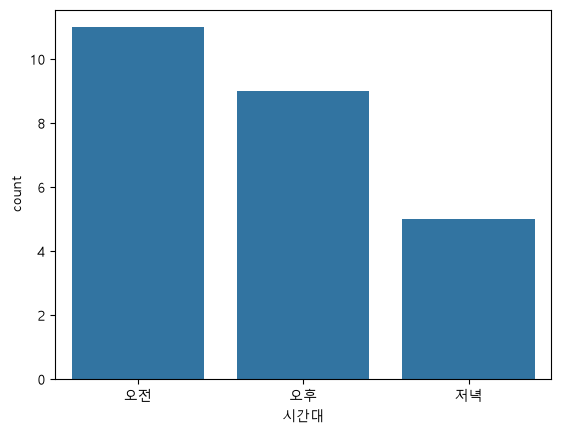

In [17]:
sns.countplot(data=df, x='시간대')

---
### 💡 오늘 배운 `.dt` 한눈에

| 코드 | 하는 일 | 결과 예 |
|------|---------|---------|
| `pd.to_datetime(s)` | 문자열 → 날짜형 | `'2025-03-13'` → `Timestamp` |
| `.dt.year / month / day` | 연·월·일 | `2025`, `3`, `13` |
| `.dt.hour` | 시(시간) | `8` |
| `.dt.dayofweek` | 요일 숫자(월0~일6) | `3` (목) |
| `.dt.strftime('%Y-%m')` | 원하는 형식의 문자열 | `'2025-03'` |

> ✨ 핵심 : **먼저 `to_datetime` 으로 날짜형으로 바꿔야** `.dt` 를 쓸 수 있습니다.
> 문자열(`.str`) → 날짜(`.dt`) 로 이어지는 흐름을 기억하세요.
